# 02 – Model: YOLO fine-tunen, evalueren en toepassen op onze video

Dit notebook traint een YOLO-detector op de dataset uit `01_split_images.ipynb`, evalueert hem eerlijk
(val en test), en maakt een video van onze wedstrijdclip met de detecties erop.

Inhoud:
1. De keuzes in één overzicht
2. Instellingen
3. Omgeving: welke GPU?
4. (optioneel) Snelheidstest: hoe lang duurt één epoch?
5. Trainen
6. Het trainingsverloop lezen
7. Evaluatie op val en test
8. Voorbeelden bekijken
9. Video met detecties
10. Export voor de minimap (OpenVINO) en logboek

> **Kernel: `venv-xpu`** (PyTorch-XPU **2.8.0** met Intel Arc-ondersteuning, zie `README.md`). Vereist een recente
> Intel-grafische driver; met een te oude driver of met PyTorch-XPU 2.15 crasht de kernel.
> **Duur op deze laptop:** ±10 min per epoch (1920 px, batch 2) → 100 epochs ±17 u, met early stopping
> waarschijnlijk ±9–10 u. Het GPU-geheugen zit bijna vol (17,3 van 17,8 GB): sluit zware programma's tijdens het trainen.
> Eerst `01_split_images.ipynb` draaien: dat maakt `dataset/`.

## 1. De keuzes in één overzicht

| Keuze | Waarde | Waarom |
|---|---|---|
| Startmodel | `yolo26l.pt` (COCO-voorgetraind) | **Transfer learning**: het model kent al "persoon" en "sportbal" uit COCO (118 000 foto's); wij leren het enkel onze 5 klassen. Met ±50 trainingsbeelden is van nul beginnen onmogelijk. *Large* i.p.v. *small/medium*: meer capaciteit voor het fijne onderscheid (team, kleine bal); de training mag een nacht duren. |
| Image size | **1920** | Originele resolutie: de bal blijft ±17 px (zie `01`, sectie 4). Bij 640 is hij ±6 px en vond ons eerste model hem nooit. |
| Epochs | max. **100** | Bovengrens; meestal stopt de training vroeger door early stopping. |
| Early stopping | `patience = 15` | Stop als de val-score 15 epochs niet meer verbetert: verder trainen leert dan vooral de train-beelden vanbuiten (overfitting) en kost enkel tijd. |
| Batch | 2 | Bij 1920 px past er weinig in het GPU-geheugen (gemeten: 17,3 van 17,8 GB). Ultralytics telt gradiënten op tot een nominale batch van 64 (`nbs`), dus het leren blijft stabiel. |
| Leersnelheid | cosinus (`cos_lr`) | Daalt geleidelijk naar het einde: grote stappen in het begin, fijne afstelling op het einde. |
| Augmentatie | zie sectie 2 | Elke epoch een andere variant van elk beeld, zodat 50 beelden niet vanbuiten geleerd worden. |
| `close_mosaic` | 10 | De laatste 10 epochs zonder mosaic: het model eindigt op realistische, volledige beelden. |
| Beste model | `best.pt` | Het epoch met de hoogste val-*fitness* (vooral mAP50-95), niet het laatste epoch. |
| Eindscore | **test**-set | Val is gebruikt om te stoppen en `best.pt` te kiezen; enkel test is nog "nieuw". |

In [1]:
import csv
import time
from datetime import date
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import torch
import yaml
from ultralytics import YOLO

## 2. Instellingen

Alles wat je zou willen aanpassen staat hier. **Augmentatie** (wat YOLO elke epoch willekeurig met een train-beeld doet):

| Parameter | Waarde | Uitleg |
|---|---|---|
| `mosaic` | 1.0 | 4 train-beelden in één beeld: meer spelers en ballen per beeld, op andere plaatsen en schalen |
| `scale` | 0.5 | in- en uitzoomen tot ±50 %: de bal komt in meer groottes voor |
| `translate` | 0.1 | beeld tot 10 % verschuiven |
| `fliplr` | 0.5 | horizontaal spiegelen: een veld is links-rechts symmetrisch, shirtkleuren veranderen niet |
| `hsv_h` | 0.01 | **heel kleine** kleurtint-verschuiving: blauw (PSG) en geel (Inter) moeten herkenbaar blijven |
| `hsv_s`, `hsv_v` | 0.5, 0.4 | verzadiging en helderheid variëren: schaduw, zon, belichting |
| `degrees` | 0 | geen rotatie: een broadcastcamera kantelt niet |
| `mixup` | 0 | twee beelden doorzichtig over elkaar: onrealistisch voor dit beeld |

In [2]:
NB_DIR = Path.cwd()                                   # kobe/notebooks/
ROOT = next(p for p in [NB_DIR, *NB_DIR.parents] if (p / "data" / "dataset_yolo").exists())
DATA_YAML = NB_DIR / "dataset" / "data.yaml"          # made by 01_split_images.ipynb
RUNS_DIR = NB_DIR / "runs"
VIDEO = ROOT / "data" / "raw_video" / "match.mp4"
EXPERIMENTS_CSV = NB_DIR / "experiments.csv"

MODEL = "yolo26l.pt"
IMGSZ = 1920
EPOCHS = 100
PATIENCE = 15
BATCH = 2
RUN_NAME = f"{Path(MODEL).stem}_{IMGSZ}"             # output in runs/<RUN_NAME>/

AUGMENT = dict(mosaic=1.0, scale=0.5, translate=0.1, fliplr=0.5, hsv_h=0.01, hsv_s=0.5, hsv_v=0.4,
               degrees=0.0, mixup=0.0)

RUN_SPEED_TEST = False   # section 4: one short epoch to estimate the training time
RUN_TRAINING = True      # False = only evaluate an existing runs/<RUN_NAME>/weights/best.pt

assert DATA_YAML.exists(), "dataset/data.yaml not found: run 01_split_images.ipynb first"
print(yaml.safe_load(DATA_YAML.read_text()))

{'path': 'C:\\Users\\kobev\\Documents\\semester 1\\3APPAI - Deep Learning\\CV-Challenge\\kobe\\notebooks\\dataset', 'train': 'train/images', 'val': 'val/images', 'test': 'test/images', 'nc': 5, 'names': ['ball', 'player_A', 'player_B', 'player_B_goal_keeper', 'referee']}


## 3. Omgeving: welke GPU?

Ultralytics kan trainen op een NVIDIA-GPU (`cuda`), een **Intel GPU** (`xpu`, via de PyTorch-XPU-versie) of op de CPU.
We kiezen automatisch het snelste dat beschikbaar is. Op de CPU duurt één epoch op 1920 px met een *large* model
uren: dan is trainen niet zinvol.

In [3]:
if torch.cuda.is_available():
    DEVICE = 0
    print("NVIDIA GPU:", torch.cuda.get_device_name(0))
elif hasattr(torch, "xpu") and torch.xpu.is_available():
    DEVICE = "xpu"
    props = torch.xpu.get_device_properties(0)
    print(f"Intel GPU: {props.name}, {props.total_memory / 1e9:.1f} GB (shared with the system)")
else:
    DEVICE = "cpu"
    print("No GPU found: training on the CPU will be very slow")
print("torch", torch.__version__, "| device:", DEVICE)

Intel GPU: Intel(R) Arc(TM) Graphics, 17.8 GB (shared with the system)
torch 2.8.0+xpu | device: xpu


## 4. (optioneel) Snelheidstest

Voordat we een hele nacht trainen: één epoch op een deel van de data (`fraction`) om de tijd per epoch te schatten,
en te zien of batch 2 in het geheugen past. Zet `RUN_SPEED_TEST = True` in sectie 2 om dit te doen.

In [4]:
if RUN_SPEED_TEST:
    t0 = time.time()
    YOLO(MODEL).train(data=str(DATA_YAML), imgsz=IMGSZ, epochs=1, batch=BATCH, device=DEVICE, fraction=0.5,
                      project=str(RUNS_DIR), name="speedtest", exist_ok=True, workers=0, plots=False, val=False)
    seconds = time.time() - t0
    full_epoch = seconds / 0.5  # half of the train images
    print(f"\n1 epoch on 50% of the data: {seconds / 60:.1f} min -> full epoch ±{full_epoch / 60:.1f} min "
          f"(+ validation) -> {EPOCHS} epochs ±{EPOCHS * full_epoch / 3600:.1f} h (without early stopping)")

## 5. Trainen

- De voorgetrainde gewichten (`yolo26l.pt`) worden automatisch gedownload.
- **Hervatten:** als de training onderbroken werd (laptop uit, crash), gaat deze cel verder vanaf het laatste
  epoch (`last.pt`) in plaats van opnieuw te beginnen.
- Tijdens het trainen print ultralytics per epoch de losses en de val-scores.

In [5]:
run_dir = RUNS_DIR / RUN_NAME
last = run_dir / "weights" / "last.pt"

if RUN_TRAINING and last.exists():
    print("resuming", last)
    YOLO(str(last)).train(resume=True)
elif RUN_TRAINING and not (run_dir / "weights" / "best.pt").exists():
    t0 = time.time()
    YOLO(MODEL).train(
        data=str(DATA_YAML), imgsz=IMGSZ, epochs=EPOCHS, patience=PATIENCE, batch=BATCH, device=DEVICE,
        project=str(RUNS_DIR), name=RUN_NAME, exist_ok=False,
        cos_lr=True, close_mosaic=10, seed=0, deterministic=True,
        cache="ram",     # 1920x1080 images decoded once and kept in memory: faster epochs
        workers=0,       # avoid multiprocessing issues on Windows / in notebooks
        plots=True, **AUGMENT,
    )
    print(f"training took {(time.time() - t0) / 3600:.1f} h")
else:
    print("using existing", run_dir / "weights" / "best.pt")

New https://pypi.org/project/ultralytics/8.4.194 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.193  Python-3.13.7 torch-2.8.0+xpu XPU:0 (Intel(R) Arc(TM) Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=c:\Users\kobev\Documents\semester 1\3APPAI - Deep Learning\CV-Challenge\kobe\notebooks\dataset\data.yaml, degrees=0.0, deterministic=True, device=xpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.5, hsv_v=0.4, imgsz=1920, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, m

## 6. Het trainingsverloop lezen

`results.png` toont per epoch:
- **box_loss**: hoe ver de voorspelde boxen van de echte liggen;
- **cls_loss**: hoe fout de klasse is (bv. PSG voorspeld waar het Inter is);
- **dfl_loss**: hoe scherp de randen van de box voorspeld worden;
- **precision / recall / mAP50 / mAP50-95** op val.

Lezen: de train-losses moeten dalen. Als de **val-losses weer stijgen** terwijl de train-losses blijven dalen,
leert het model de train-beelden vanbuiten (**overfitting**): dat is precies wat early stopping opvangt.

trained 45 epochs (max 100); best epoch 30: mAP50 0.672, mAP50-95 0.277
early stopping: no improvement for 15 epochs after epoch 30


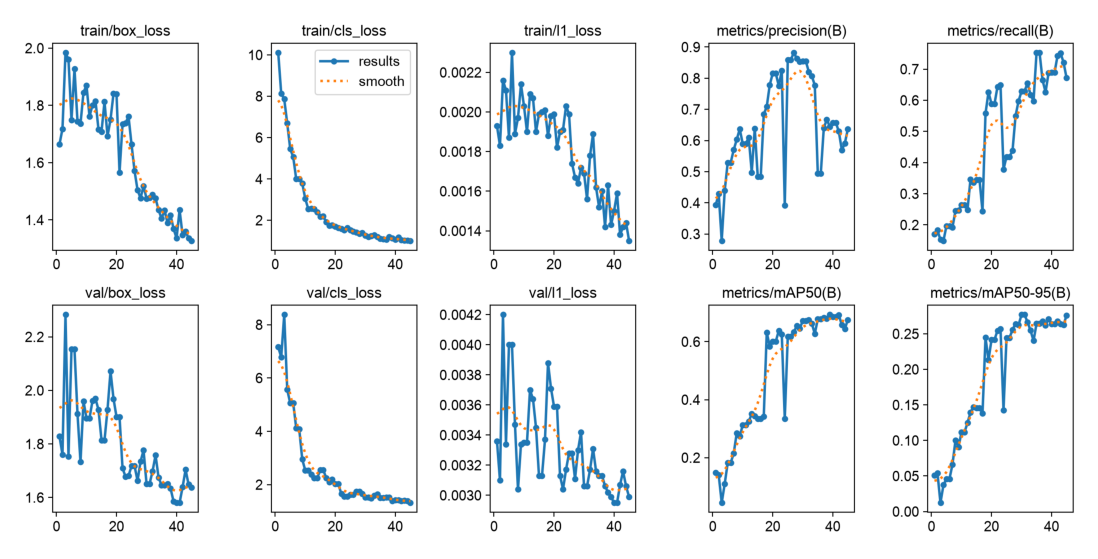

In [6]:
rows = list(csv.DictReader(open(run_dir / "results.csv")))
rows = [{k.strip(): v for k, v in r.items()} for r in rows]
best = max(rows, key=lambda r: float(r["metrics/mAP50-95(B)"]))
print(f"trained {len(rows)} epochs (max {EPOCHS}); best epoch {best['epoch']}: "
      f"mAP50 {float(best['metrics/mAP50(B)']):.3f}, mAP50-95 {float(best['metrics/mAP50-95(B)']):.3f}")
if len(rows) < EPOCHS:
    print(f"early stopping: no improvement for {PATIENCE} epochs after epoch {best['epoch']}")

plt.figure(figsize=(14, 7))
plt.imshow(plt.imread(run_dir / "results.png"))
plt.axis("off")
plt.show()

## 7. Evaluatie op val en test

- **Precision (P):** van alle voorspelde boxen, welk deel klopt?
- **Recall (R):** van alle echte objecten, welk deel is gevonden?
- **mAP50:** gemiddelde precisie als een box "juist" is vanaf 50 % overlap (IoU) met de echte box.
- **mAP50-95:** hetzelfde, gemiddeld over strengere overlap-drempels (50 % tot 95 %): beloont *precieze* boxen.
  Voor een bal van 17 px is dit streng: een paar pixels naast is al een grote IoU-daling.
- **beste conf:** de confidence-drempel met de beste balans tussen precision en recall (hoogste F1) per klasse.
  Die gebruiken we later bij de video en de minimap.

**Val** is gebruikt om `best.pt` te kiezen; **test** is de eerlijke eindscore.

In [7]:
model = YOLO(str(run_dir / "weights" / "best.pt"))
scores = {}
for split in ["val", "test"]:
    m = model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                  project=str(RUNS_DIR), name=f"{RUN_NAME}_{split}", exist_ok=True, plots=True, verbose=False)
    box, present = m.box, list(m.box.ap_class_index)
    print(f"\n=== {split} ===")
    print(f"{'class':<22}{'P':>7}{'R':>7}{'mAP50':>8}{'mAP50-95':>10}{'best conf':>11}")
    for cid, name in model.names.items():
        if cid not in present:
            print(f"{name:<22}{'(not in this split)':>43}")
            continue
        i = present.index(cid)
        p, r, ap50, ap = box.class_result(i)
        print(f"{name:<22}{p:>7.3f}{r:>7.3f}{ap50:>8.3f}{ap:>10.3f}{box.px[box.f1_curve[i].argmax()]:>11.2f}")
    print(f"{'ALL':<22}{box.mp:>7.3f}{box.mr:>7.3f}{box.map50:>8.3f}{box.map:>10.3f}")
    scores[split] = box

Ultralytics 8.4.193  Python-3.13.7 torch-2.8.0+xpu XPU:0 (Intel(R) Arc(TM) Graphics)
YOLO26l summary (fused): 188 layers, 24,749,595 parameters, 0 gradients, 86.5 GFLOPs
val: Fast image access  (ping: 0.1±0.1 ms, read: 419.1±35.1 MB/s, size: 146.2 KB)
val: Scanning C:\Users\kobev\Documents\semester 1\3APPAI - Deep Learning\CV-Challenge\kobe\notebooks\dataset\val\labels.cache... 23 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 23/23 13.8Mit/s 0.0s
WARNING NMS time limit 2.100s exceeded
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 16% ━━────────── 2/12 7.2s/it 9.9s<1:12WARNING NMS time limit 2.100s exceeded
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 3.2s/it 37.9s2.9s
                   all         23        588      0.856      0.631      0.672      0.278
Speed: 7.8ms preprocess, 542.2ms inference, 0.0ms loss, 963.7ms postprocess per image
Results saved to C:\Users\kob

**Confusion matrix (test):** rijen = voorspelde klasse, kolommen = echte klasse. De diagonaal is juist.
De rij/kolom `background` toont gemiste objecten (false negatives) en detecties waar niets is (false positives).
Typische fouten om naar te kijken: `player_A` ↔ `player_B` (verkeerd team), de bal gemist, of een witte schoen als bal.

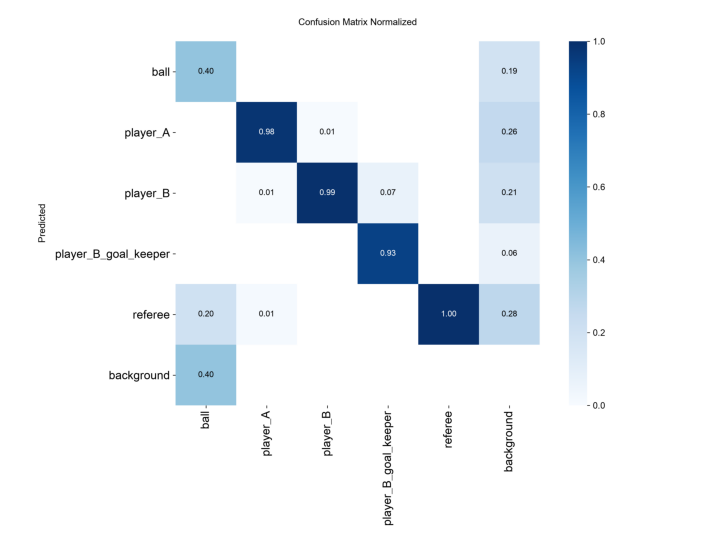

In [8]:
plt.figure(figsize=(9, 8))
plt.imshow(plt.imread(RUNS_DIR / f"{RUN_NAME}_test" / "confusion_matrix_normalized.png"))
plt.axis("off")
plt.show()

## 8. Voorbeelden bekijken

Links de echte labels van val-beelden, rechts wat het model voorspelt (met confidence).

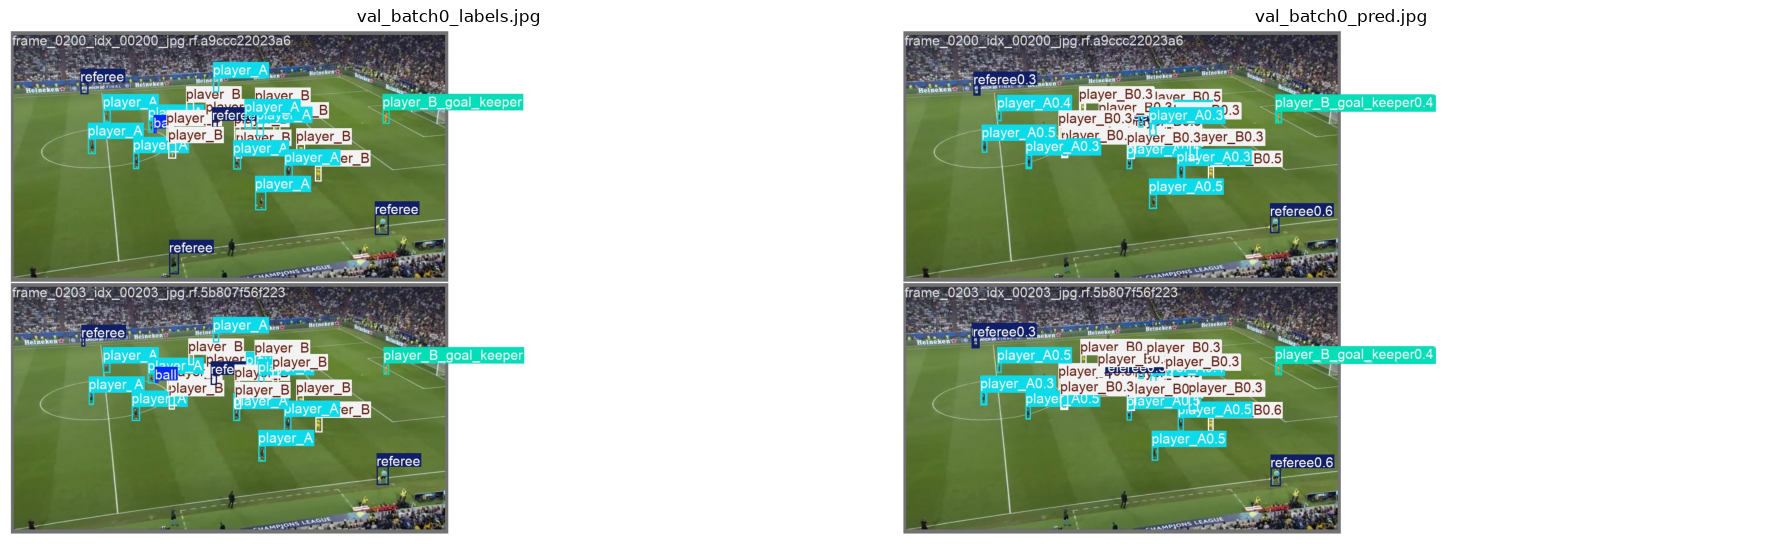

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, name in zip(axes, ["val_batch0_labels.jpg", "val_batch0_pred.jpg"]):
    ax.imshow(plt.imread(RUNS_DIR / f"{RUN_NAME}_val" / name))
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Video met detecties

Het model op alle 660 frames van onze clip. Spelers onder `CONF` worden niet getekend; voor de bal gebruiken
we een lagere drempel, omdat hij klein is en het model er minder zeker over is.
Het resultaat: `runs/<RUN_NAME>_video.mp4`.

In [10]:
CONF, BALL_CONF = 0.3, 0.15
source = str(VIDEO) if VIDEO.exists() else str(ROOT / "data" / "frames")  # the frames if the mp4 is missing
out_path = RUNS_DIR / f"{RUN_NAME}_video.mp4"
writer, t0 = None, time.time()
for n, res in enumerate(model.predict(source=source, imgsz=IMGSZ, conf=BALL_CONF, device=DEVICE,
                                      stream=True, verbose=False), start=1):
    keep = [(c == 0 and s >= BALL_CONF) or s >= CONF                   # class 0 = ball
            for c, s in zip(res.boxes.cls.tolist(), res.boxes.conf.tolist())]
    res = res[torch.tensor(keep, dtype=torch.bool)]
    frame = res.plot(line_width=2, font_size=12)
    if writer is None:
        h, w = frame.shape[:2]
        writer = cv2.VideoWriter(str(out_path), cv2.VideoWriter_fourcc(*"mp4v"), 30, (w, h))
    writer.write(frame)
    if n % 100 == 0:
        print(f"{n} frames, {(time.time() - t0) / n:.2f} s/frame")
writer.release()
print("video:", out_path)

100 frames, 0.54 s/frame
200 frames, 0.53 s/frame
300 frames, 0.53 s/frame
400 frames, 0.52 s/frame
500 frames, 0.52 s/frame
600 frames, 0.51 s/frame
video: c:\Users\kobev\Documents\semester 1\3APPAI - Deep Learning\CV-Challenge\kobe\notebooks\runs\yolo26l_1920_video.mp4


## 10. Export voor de minimap en logboek

**OpenVINO-export:** het notebook `minimap/02_minimap_video.ipynb` draait het model op de Intel Arc GPU via
OpenVINO (Intels eigen formaat: op deze laptop ±3x sneller dan PyTorch op de CPU, en het werkt ook met
een oudere driver). Half precision (`quantize=16`, FP16) halveert het geheugen met nauwelijks verschil in detecties.

**Logboek:** elke run komt als rij in `experiments.csv`, zodat runs met elkaar te vergelijken zijn.

In [11]:
model.export(format="openvino", imgsz=IMGSZ, quantize=16)  # 16 = half precision (FP16)
print("OpenVINO model:", run_dir / "weights" / "best_openvino_model")

row = {"date": date.today().isoformat(), "run": RUN_NAME, "model": MODEL, "imgsz": IMGSZ, "epochs": len(rows),
       "best_epoch": best["epoch"], "patience": PATIENCE, "batch": BATCH,
       **{f"{s}_mAP50": round(float(scores[s].map50), 4) for s in scores},
       **{f"{s}_mAP50-95": round(float(scores[s].map), 4) for s in scores}}
new = not EXPERIMENTS_CSV.exists()
with open(EXPERIMENTS_CSV, "a", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(row))
    if new:
        w.writeheader()
    w.writerow(row)
print(row)

Ultralytics 8.4.193  Python-3.13.7 torch-2.8.0+xpu CPU (Intel Core Ultra 7 155H)
YOLO26l summary (fused): 188 layers, 24,749,595 parameters, 0 gradients, 804.8 GFLOPs

PyTorch: starting from 'c:\Users\kobev\Documents\semester 1\3APPAI - Deep Learning\CV-Challenge\kobe\notebooks\runs\yolo26l_1920\weights\best.pt' with input shape (1, 3, 1920, 1920) BCHW and output shape(s) (1, 9, 75600) (50.7 MB)

OpenVINO: starting export with openvino 2026.4.1-22982-e213a147257-releases/2026/4...
OpenVINO: export success  4.6s, saved as 'c:\Users\kobev\Documents\semester 1\3APPAI - Deep Learning\CV-Challenge\kobe\notebooks\runs\yolo26l_1920\weights\best_openvino_model\' (48.4 MB)

Export complete (7.1s)
Results saved to C:\Users\kobev\Documents\semester 1\3APPAI - Deep Learning\CV-Challenge\kobe\notebooks\runs\yolo26l_1920\weights\best_openvino_model
Predict:         yolo predict task=detect model=c:\Users\kobev\Documents\semester 1\3APPAI - Deep Learning\CV-Challenge\kobe\notebooks\runs\yolo26l_1920\

## Conclusie

*(in te vullen na de training, met de cijfers hierboven)*

- Hoeveel epochs liep de training, en waar stopte early stopping?
- Hoe goed is de bal op test (P, R, mAP50)? Vergelijk met de smoke test (bal mAP 0 bij 640 px).
- Welke klassen worden verwisseld volgens de confusion matrix, en hoe verklaar je dat (labels, data, beeld)?
- Wat zou je als volgende verbetering doen (meer labels in test, andere augmentatie, ...)?